<a href="https://colab.research.google.com/github/HeiKol258/kobe-data-business-colab/blob/main/lecture03/lecture3_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/okumura-kobe/kobe-data-business/blob/main/lecture03/lecture3_notebook.ipynb)

# 後期大学院演習「データで動かす社会とビジネス」
## 第3回　演習 Notebook

**テーマ：データを読み、比較する**
― 問いに答えるために、データを分けて見る ―

---

### この Notebook の使い方

- **STEP 1 はコードなし**：第2回のワークシートを手元に用意して、問いと設計表を確認してください
- **STEP 2〜4 でコードを実行**：`____` を自分の問いに合わせて埋めてください
- **STEP 5・6 はコードなし**：分析結果をワークシートに記録してください

**今日の核心**
> 比較の切り方で、見えるものが変わる。
> 全体 → 1軸比較 → 2軸比較 と深めていく。

---

| | |
|---|---|
| 学籍番号 | |
| 氏名 | |
| 実施日 | |

---
## Step 0　準備

In [1]:
# ライブラリの読み込み（変更不要）
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import urllib.request, zipfile, io, warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', '{:.2f}'.format)

matplotlib.rcParams['axes.spines.top']   = False
matplotlib.rcParams['axes.spines.right'] = False
matplotlib.rcParams['figure.figsize']    = (11, 4)

print('Ready')

Ready


In [2]:
# データの読み込み（変更不要）
url = "https://raw.githubusercontent.com/okumura-kobe/kobe-data-business/main/data/bike.csv"
df = pd.read_csv(url)

print(f'Rows: {df.shape[0]:,}  Cols: {df.shape[1]}')
df.head()

Rows: 17,379  Cols: 17


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.29,0.81,0.00,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.27,0.80,0.00,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.27,0.80,0.00,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.29,0.75,0.00,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.29,0.75,0.00,0,1,1


---
## STEP 1　第2回の問いを再確認する

**コードなし。第2回のワークシートを参照してください。**

以下をこのセルのコメントに転記してください。

In [ ]:
# 第2回の設計表より転記する
#
# 【修正後の問い（②）】
# 平日・休日別に、時間帯別の平均cntと登録・カジュアル利用者の内訳はどう異なり、重点配置すべき上位3時間帯はいつか。
#
# 【目的変数（③）】  例: 'cnt', 'registered', 'casual'
# cnt, registered, casual
#
# 【比較・説明変数（④）】  例: 'workingday', 'weathersit', 'hr'
# hr, workingday, weathrsit, registered, casual
#
# 【判断基準（⑦）】
# 各区分で平均cntが上位3時間帯に入れば重点配置する。天候が悪い日は平均需要に合わせて人数を減らす。
#
# 【今日の分析ストーリー】全体 → 1軸 → 2軸 と、どの順番で比較を深めるか
# 全体平均を確認した後、1軸ではworkingdayで平日・休日を比較する。2軸ではhrを加えて時間帯別の違いを見る。
# 最後にregisteredとcasualの内訳も確認し、区分別の重点時間帯を判断する。


---
## STEP 2　1軸比較（最初の切り口）

まず1つの変数で比較します。
自分の比較変数（④）の中から最も重要だと思う1つを選んでください。

In [8]:
# 2-1　1軸比較：目的変数を1つの変数で集計する
# 比較変数：workingday、目的変数：cnt
result_1axis = df.groupby('workingday')['cnt'].mean()
print('1軸比較の結果:')
print(result_1axis.round(1))

1軸比較の結果:
workingday
0   181.40
1   193.20
Name: cnt, dtype: float64


In [6]:
# 2-2　比較の文脈を追加で確認する（必要に応じて）
# 件数（データのバランス）も確認しておく

count_1axis = df.groupby('workingday').size()
print('グループ別件数:')
print(count_1axis)

グループ別件数:
workingday
0     5514
1    11865
dtype: int64


---
## STEP 3　2軸比較（切り口を増やす）

STEP 2の比較に軸を1つ加えます。
同じデータでも、切り方を変えると何が変わるかを確認してください。

In [10]:
# 3-1　2軸比較：平日・休日と時間帯で集計する
result_2axis = df.groupby(['workingday', 'hr'])['cnt'].mean()
print('2軸比較の結果:')
print(result_2axis.round(1))

2軸比較の結果:
workingday  hr
0           0     90.80
            1     69.50
            2     53.20
            3     25.80
            4      8.30
            5      8.70
            6     18.70
            7     43.40
            8    105.70
            9    171.60
            10   255.90
            11   315.30
            12   366.30
            13   372.70
            14   364.60
            15   358.80
            16   352.70
            17   323.50
            18   281.10
            19   231.70
            20   174.70
            21   142.10
            22   116.10
            23    85.90
1           0     36.80
            1     16.60
            2      8.70
            3      4.90
            4      5.40
            5     24.90
            6    102.50
            7    290.60
            8    477.00
            9    241.50
            10   135.40
            11   158.20
            12   200.80
            13   198.40
            14   183.60
            15   201.30
            16  

In [11]:
# 3-2　時間帯を行、平日・休日を列にして整理する
pivot = pd.pivot_table(
    df,
    index='hr',
    columns='workingday',
    values='cnt',
    aggfunc='mean'
)
print(pivot.round(1))

workingday      0      1
hr                      
0           90.80  36.80
1           69.50  16.60
2           53.20   8.70
3           25.80   4.90
4            8.30   5.40
5            8.70  24.90
6           18.70 102.50
7           43.40 290.60
8          105.70 477.00
9          171.60 241.50
10         255.90 135.40
11         315.30 158.20
12         366.30 200.80
13         372.70 198.40
14         364.60 183.60
15         358.80 201.30
16         352.70 293.10
17         323.50 525.30
18         281.10 492.20
19         231.70 348.40
20         174.70 249.70
21         142.10 186.30
22         116.10 138.40
23          85.90  88.70


---
## STEP 4　可視化（問いに合ったグラフを選ぶ）

STEP 2または3の結果をグラフで確認します。
自分の問いに最も適切なグラフを選んでください。

**選択肢：**
- 棒グラフ：グループ間の大小を比較するとき
- 折れ線グラフ：時間帯など連続的な変化を見るとき
- 箱ひげ図：分布のばらつきを見るとき

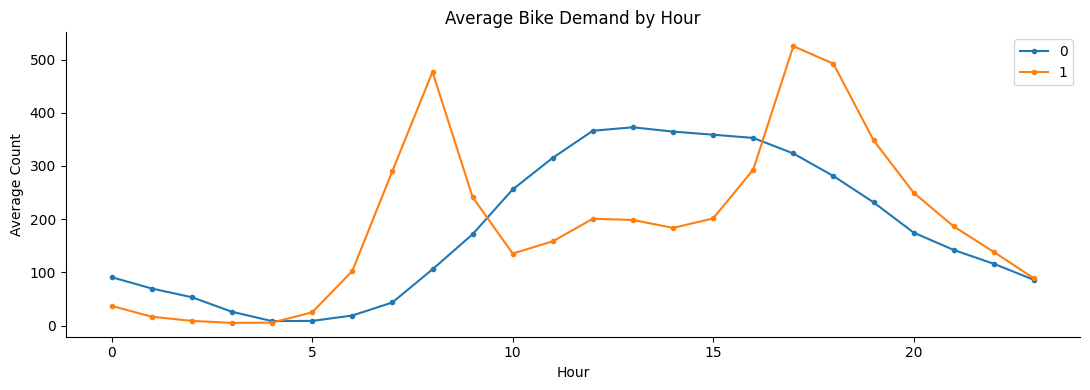

In [14]:
# 4-1　可視化する
# TODO: 自分の問いに合ったグラフを作成してください

fig, ax = plt.subplots()

# ── 棒グラフの例 ──────────────────────────────────────────────────────
# result_1axis.plot(kind='bar', ax=ax, color='#1E2761', alpha=0.85)

# ── 折れ線グラフの例（時間帯×グループ）──────────────────────────────
# for group_val in df[____].unique():
#     subset = df[df[____] == group_val].groupby(____)[____].mean()
#     ax.plot(subset.index, subset.values, label=str(group_val), marker='o', markersize=3)
# ax.legend()

# ── 自分のコードをここに書く ──────────────────────────────────────────
for group_val in df['workingday'].unique():
    subset = df[df['workingday'] == group_val].groupby('hr')['cnt'].mean()
    ax.plot(subset.index, subset.values, label=str(group_val), marker='o', markersize=3)
ax.legend()

ax.set_title('Average Bike Demand by Hour')
ax.set_xlabel('Hour')
ax.set_ylabel('Average Count')
plt.tight_layout()
plt.show()

---
## STEP 5　判断基準に照らした示唆

**コードなし。ワークシートの STEP 5 に記入してください。**

以下をコメントとして記録してください。

In [ ]:
# STEP 5：判断基準に照らした示唆を記録する
#
# 【第2回の判断基準（⑦）を転記】
# 各区分で平均cntが上位3時間帯に入れば重点配置する。天候が悪い日は平均需要に合わせて人数を減らす。
#
# 【今日の分析から言える示唆】
# 判断基準に照らして、今日の結果はどう解釈できるか？
# 意思決定課題に対して何が言えるか？
#
# 基準に従い、平日は8時・17時・18時、休日は12時・13時・14時を重点配置する。利用者内訳も見ると、平日の朝夕は登録者中心、休日の昼間はカジュアル利用が増えるため、同じ配置を毎日続けない。悪天候時は平均需要を確認して人数を調整する。



---
## STEP 6　言えること・言えないこと

**コードなし。ワークシートの STEP 6 に記入してください。**

In [ ]:
# STEP 6：言えること・言えないことを記録する
#
# 【今日の分析から「言えること」】
# 観測されたパターン・傾向
#
# 平均利用件数は平日・休日と時間帯で異なる。平日は朝夕、休日は昼間が高く、重点時間帯を分ける必要がある。
#
# 【今日の分析では「言えないこと」】
# 相関 ≠ 因果。施策効果を言うには何が必要か？
#
# この差の原因、配置変更の効果、駅ごとの必要台数までは分からない。天候・季節などが同時に影響している可能性がある。
#
# 【観測と因果の区別】
# 今日見えたパターンは「相関」か「因果」か？
#
# 見えたパターンは相関であり、因果とは言えない。施策効果を言うには、比較可能な対照群を置いた実験、または他の条件を調整した分析と施策前後のデータが必要である。
#


---
## まとめ

### 今日学んだこと

| STEP | 内容 |
|---|---|
| STEP 1 | 第2回の問い・設計表を起点に比較を設計した |
| STEP 2 | 1軸比較で最初の切り口を確認した |
| STEP 3 | 2軸比較で見えなかった構造を発見した |
| STEP 4 | 問いに合ったグラフで可視化した |
| STEP 5 | 判断基準に照らして示唆を整理した |
| STEP 6 | 「言えること」と「言えないこと」を区別した |

### 今日の核心

> **比較の切り方で、見えるものが変わる。**
> 全体だけ見ていると見えない構造が、軸を増やすことで浮かび上がる。
> しかし観測パターンから施策効果（因果）は言えない。それは第5〜9回へ。

---

### 次回（第4回）：分析できるデータを作る

**事前課題**
- 今日の分析で「こう比較したかった」と思ったことをメモしておく
- BEEF+ の第4回配布資料を読む
- 今日のグラフ・集計結果を保存しておく（課題提出に使用）